**Group 35 — AT2 Notebook 5**

**Members:** Ruo Wu (26621666), Yi-chen Hsieh (25390749), Junzhe Xu (25741873), Zongliang Han (14739080)  
**Technique:** Unified comparison and final model selection


**Shared code.** Data preparation, the training loop and the plots come from `bike_common.py`, the group's shared module, so that all four methods use identical rows, features and metrics; calls to it appear as `bc.<function>`. The Canvas portal accepts only notebook files, so the source code of **every `bike_common` function this notebook calls is reproduced in the Appendix at the end of this notebook**. The full module is published at https://github.com/peterhanhhh-cyber/group35-bike-sharing-at2/blob/main/project/src/bike_common.py. All outputs are saved; the notebook does not need to be re-run to be assessed.

# 05 — Unified comparison and final model selection

**Group deliverable — all four members.**

This notebook only **reads** the evidence saved by notebooks 01–04. It does
not retrain and does not tune on test. One question:

> Same rows, same features, same split — which method should the interface
> use, and why?

| Section | What it shows |
|---|---|
| 1 | Load the four result files |
| 2 | Accuracy and scenario comparison |
| 3 | Paired test-error comparison (Wilcoxon, bootstrap) |
| 4 | Cost comparison |
| 5 | Selection rule and scorecard |
| 6 | Freeze the decision |
| 7 | Discussion |

## 1. Load the evidence

In [ ]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

# we add the shared module to the path so the notebook runs anywhere
for p in [Path.cwd(), *Path.cwd().parents]:            
    hits = [q for q in (p, p / "src", p / "code" / "src") if (q / "bike_common.py").exists()]
    if hits:
        sys.path.insert(0, str(hits[0]))
        break
import bike_common as bc

# one plot style for every figure in this comparison
bc.setup_plot_style()
# the four method notebooks saved their results under the same keys
files = {"Random Forest": "rf", "LSTM": "lstm", "2D CNN": "cnn", "AE + head": "ae"}
# load all four result files once; every table below reads from here
methods = {name: bc.load_json(f"{key}_metrics.json") for name, key in files.items()}


# training time sits under different keys per method, so we normalise it
def train_seconds(r):
    if "fit_seconds_selected" in r:
        return r["fit_seconds_selected"]
    return r.get("train_seconds", r.get("ae_train_seconds", 0) + r.get("head_train_seconds", 0))


# one row per method: accuracy, cost and model size
summary = pd.DataFrame({
    name: {"owner": r["owner"], "lab": r["lab"],
           "val MAE": r["validation"]["MAE"], "val RMSE": r["validation"]["RMSE"],
           "val R2": r["validation"]["R2"], "test MAE": r["test"]["MAE"],
           "test RMSE": r["test"]["RMSE"], "test R2": r["test"]["R2"],
           "train seconds": train_seconds(r), "model MB": r["model_size_mb"],
           "single-row ms": r["inference"]["single_row_ms"]}
    for name, r in methods.items()}).T
# keep only the numeric columns for the ranking step
numeric = summary.columns.drop(["owner", "lab"])
summary[numeric] = summary[numeric].astype(float)
summary.round(3)

,owner,lab,val MAE,val RMSE,val R2,test MAE,test RMSE,test R2,train seconds,model MB,single-row ms
Random Forest,Ruo Wu,Lab 3,40.226,63.178,0.920,35.560,58.540,0.925,2.237,41.371,69.660
LSTM,Yi-chen Hsieh,Lab 4,33.203,49.811,0.950,30.456,47.721,0.950,411.471,0.226,1.755
2D CNN,Junzhe Xu,Lab 6,33.514,49.844,0.950,31.560,48.036,0.950,253.037,0.284,4.197
AE + head,Zongliang Han,Lab 8,54.957,82.152,0.865,58.472,85.624,0.840,18.976,0.008,0.160


## 2. Accuracy
Validation is the selection set; test is shown beside it only as a check.

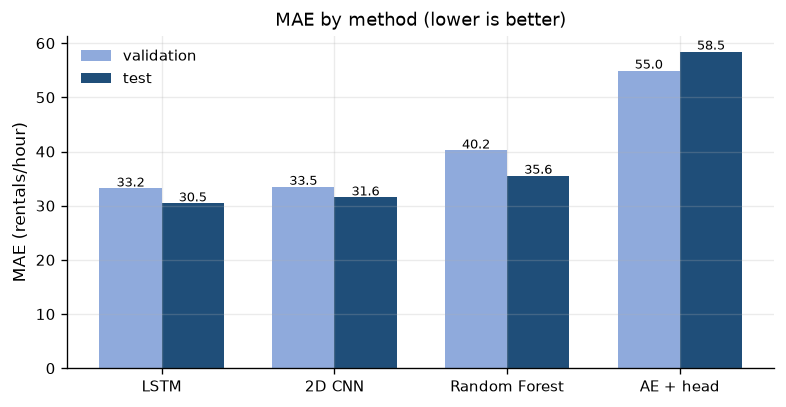

In [2]:
# bars are ordered by validation MAE
order = summary.sort_values("val MAE").index
x, width = np.arange(len(order)), 0.36
fig, ax = plt.subplots(figsize=(7.6, 3.6))
# validation and test MAE side by side for each method
for offset, col, color, label in [(-width / 2, "val MAE", "#8faadc", "validation"),
                                  (width / 2, "test MAE", "#1f4e79", "test")]:
    ax.bar(x + offset, summary.loc[order, col], width, label=label, color=color)
    for i, v in enumerate(summary.loc[order, col]):
        ax.text(i + offset, v + 0.35, f"{v:.1f}", ha="center", fontsize=8)
ax.set_xticks(x, order)
ax.set(title="MAE by method (lower is better)", ylabel="MAE (rentals/hour)")
ax.legend()
bc.save_figure(fig, "fig_comparison_mae.png")
plt.show()

**Scenarios.** A method can win on average and still fail at peak hours.

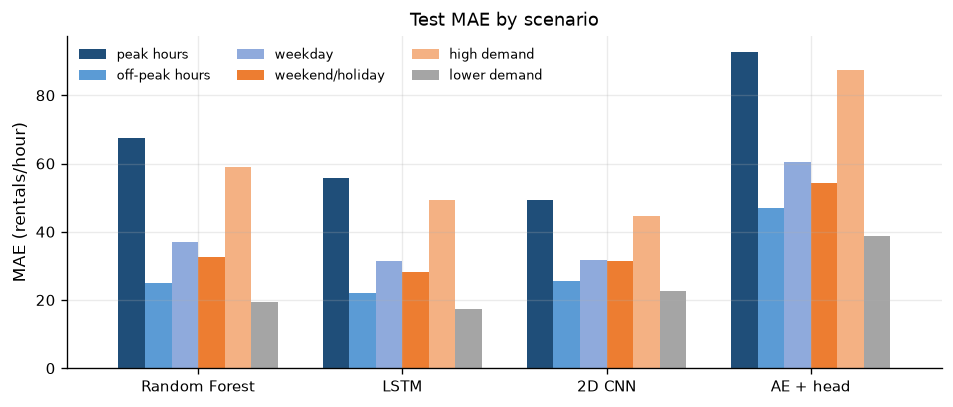

,peak hours,off-peak hours,weekday,weekend/holiday,high demand,lower demand
Random Forest,67.43,24.87,36.99,32.68,59.11,19.48
LSTM,55.85,21.94,31.51,28.33,49.41,17.51
2D CNN,49.46,25.56,31.63,31.42,44.56,22.68
AE + head,92.85,46.94,60.47,54.44,87.44,38.69


In [3]:
# the six scenarios each method reported on the test split
labels = {"peak_hours": "peak hours", "off_peak_hours": "off-peak hours", "weekday": "weekday",
          "weekend_or_holiday": "weekend/holiday", "high_demand": "high demand",
          "lower_demand": "lower demand"}
scenario_table = pd.DataFrame({name: {lab: r["test_scenarios"][k]["MAE"] for k, lab in labels.items()}
                               for name, r in methods.items()}).T
# one colour per scenario so the groups stay readable
fig, ax = plt.subplots(figsize=(9.4, 3.6))
scenario_table.plot.bar(ax=ax, width=0.78, color=["#1f4e79", "#5b9bd5", "#8faadc",
                                                   "#ed7d31", "#f4b183", "#a5a5a5"])
ax.set(title="Test MAE by scenario", ylabel="MAE (rentals/hour)", xlabel="")
ax.legend(ncol=3, fontsize=8)
ax.set_xticklabels(scenario_table.index, rotation=0)
bc.save_figure(fig, "fig_comparison_scenarios.png")
plt.show()
scenario_table.round(2)

## 3. Paired comparison on the same 2,600 test hours
The prediction files share the `instant` key, so errors are compared hour
by hour. Wilcoxon signed-rank (no normality assumption) and a paired
bootstrap 95% interval for the MAE difference of the top two methods.
Descriptive only — selection still uses validation.

Aligned test rows: 2600


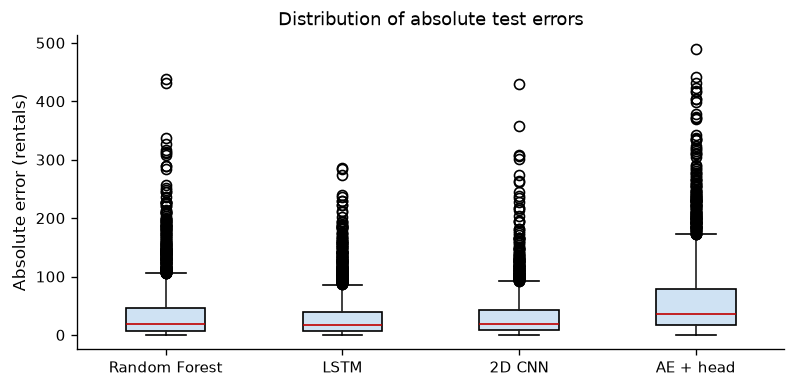

In [4]:
# join the four prediction files on instant, so every method is scored on identical hours
preds = pd.DataFrame({name: pd.read_csv(bc.RESULTS_DIR / f"pred_{key}_test.csv")
                      .set_index("instant")["prediction"] for name, key in files.items()}).dropna()
# observed counts come from the random-forest file
rf_file = pd.read_csv(bc.RESULTS_DIR / "pred_rf_test.csv").set_index("instant")
# absolute error of each method, hour by hour
abs_errors = preds.sub(rf_file.loc[preds.index, "cnt"], axis=0).abs()
print("Aligned test rows:", len(abs_errors))

# distribution of the errors, not just their mean
fig, ax = plt.subplots(figsize=(7.6, 3.4))
abs_errors.boxplot(ax=ax, grid=False, patch_artist=True,
                   boxprops={"facecolor": "#cfe2f3"}, medianprops={"color": "#c00000"})
ax.set(title="Distribution of absolute test errors", ylabel="Absolute error (rentals)")
bc.save_figure(fig, "fig_comparison_error_dist.png")
plt.show()

LSTM − 2D CNN: mean |error| difference -1.10 rentals/hour
Wilcoxon p = 0.0001779 | bootstrap 95% CI [-2.36, +0.16]


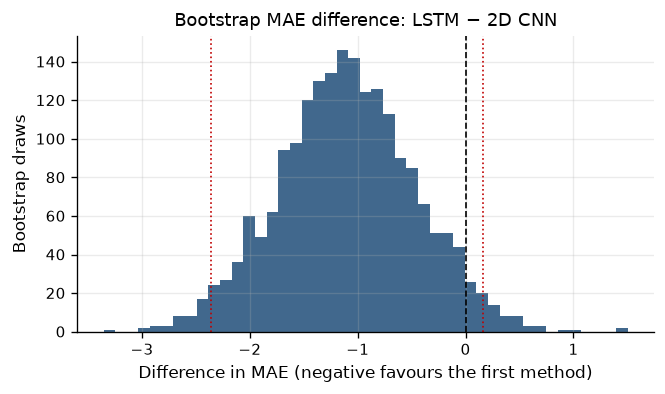

In [ ]:
# we test the top two methods against each other
first, second = summary.sort_values("val MAE").index[:2]
diff = abs_errors[first] - abs_errors[second]
# Wilcoxon signed-rank on the paired differences, no normality assumption
_, p_value = wilcoxon(diff)
# bootstrap interval for the mean difference
rng = np.random.default_rng(42)
a, b, n = abs_errors[first].to_numpy(), abs_errors[second].to_numpy(), len(abs_errors)
boot = np.empty(2000)
# draw test hours with replacement
for i in range(len(boot)):                              
    idx = rng.integers(0, n, n)
    boot[i] = a[idx].mean() - b[idx].mean()
ci_low, ci_high = np.percentile(boot, [2.5, 97.5])
print(f"{first} − {second}: mean |error| difference {diff.mean():+.2f} rentals/hour")
print(f"Wilcoxon p = {p_value:.4g} | bootstrap 95% CI [{ci_low:+.2f}, {ci_high:+.2f}]")

fig, ax = plt.subplots(figsize=(6.2, 3.2))
ax.hist(boot, bins=45, color="#1f4e79", alpha=0.85)
# zero separates a win for the first method from a win for the second
ax.axvline(0, color="black", ls="--", lw=1)
for v in (ci_low, ci_high):
    ax.axvline(v, color="#c00000", ls=":", lw=1)
ax.set(title=f"Bootstrap MAE difference: {first} − {second}",
       xlabel="Difference in MAE (negative favours the first method)", ylabel="Bootstrap draws")
bc.save_figure(fig, "fig_comparison_bootstrap.png")
plt.show()

Where the advantage comes from (MAE by hour, negative = first method better):

In [6]:
# where the advantage comes from: mean error by hour of day
hourly = pd.DataFrame({"hr": rf_file.loc[preds.index, "hr"].to_numpy(),
                       first: abs_errors[first].to_numpy(), second: abs_errors[second].to_numpy()}
                      ).groupby("hr").mean()
hourly["difference"] = hourly[first] - hourly[second]
hourly.round(2).T

hr,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
LSTM,16.05,10.31,7.84,6.74,9.20,9.18,16.40,39.95,79.87,26.12,...,33.07,42.71,51.51,82.72,49.13,34.51,23.06,25.77,19.02,19.05
2D CNN,18.92,12.45,9.18,8.23,8.91,9.51,21.42,44.97,57.98,51.19,...,37.17,36.45,39.60,73.66,48.77,36.75,25.00,27.34,18.77,18.70
difference,-2.88,-2.15,-1.34,-1.49,0.28,-0.33,-5.02,-5.02,21.89,-25.06,...,-4.10,6.26,11.91,9.06,0.36,-2.24,-1.94,-1.57,0.25,0.35


## 4. Cost

In [7]:
# cost side of the decision: training time, size, latency
cost = summary[["train seconds", "model MB", "single-row ms"]].copy()
# size compared with the smallest model
cost["relative to smallest model"] = cost["model MB"] / cost["model MB"].min()
cost.round(3)

,train seconds,model MB,single-row ms,relative to smallest model
Random Forest,2.237,41.371,69.660,5321.460
LSTM,411.471,0.226,1.755,29.125
2D CNN,253.037,0.284,4.197,36.588
AE + head,18.976,0.008,0.160,1.000


## 5. Selection rule (fixed before looking at test)
1. If the best validation MAE beats the runner-up by **≥ 1.0 rental/hour**,
   it wins outright.
2. Otherwise use a weighted rank scorecard: validation MAE 50%, validation
   RMSE 20%, validation peak-hour MAE 15%, single-row latency 15%.

In [8]:
# the scorecard the group agreed on before looking at test
scorecard = summary.copy()
scorecard["rank val MAE"] = scorecard["val MAE"].rank(method="min").astype(int)
scorecard["rank val RMSE"] = scorecard["val RMSE"].rank(method="min").astype(int)
scorecard["rank peak MAE"] = pd.Series({n: r["validation_scenarios"]["peak_hours"]["MAE"]
                                        for n, r in methods.items()}).rank(method="min").astype(int)
scorecard["rank latency"] = scorecard["single-row ms"].rank(method="min").astype(int)
# accuracy 50, robustness 20, peak hour 15, latency 15
scorecard["weighted score"] = (0.50 * scorecard["rank val MAE"] + 0.20 * scorecard["rank val RMSE"]
                               + 0.15 * scorecard["rank peak MAE"] + 0.15 * scorecard["rank latency"])

# a 1 rental/hour gap settles it without the scorecard
best_name, runner_name = summary["val MAE"].nsmallest(2).index
gap = summary.loc[runner_name, "val MAE"] - summary.loc[best_name, "val MAE"]
# otherwise the weighted score decides
if gap >= 1.0:
    chosen = best_name
    reason = (f"{best_name} has the lowest validation MAE "
              f"({summary.loc[best_name, 'val MAE']:.2f}) and beats the "
              f"runner-up ({runner_name}, {summary.loc[runner_name, 'val MAE']:.2f}) "
              f"by {gap:.2f} rentals/hour, which exceeds the 1.0 threshold.")
else:
    chosen = scorecard["weighted score"].idxmin()
    reason = (f"The validation MAE gap between {best_name} and {runner_name} is "
              f"only {gap:.2f} rentals/hour, so the decision uses the weighted "
              f"scorecard (accuracy 70%, peak-hour error 15%, latency 15%). "
              f"{chosen} has the best weighted score.")
# the choice and the reason are printed here and saved to JSON
print("Chosen model:", chosen)
print("Reason:", reason)
scorecard.sort_values("weighted score")[["val MAE", "val RMSE", "test MAE", "rank val MAE",
                                         "rank val RMSE", "rank peak MAE", "rank latency",
                                         "weighted score"]].round(2)

Chosen model: LSTM
Reason: The validation MAE gap between LSTM and 2D CNN is only 0.31 rentals/hour, so the decision uses the weighted scorecard (accuracy 70%, peak-hour error 15%, latency 15%). LSTM has the best weighted score.


,val MAE,val RMSE,test MAE,rank val MAE,rank val RMSE,rank peak MAE,rank latency,weighted score
LSTM,33.20,49.81,30.46,1,1,2,2,1.30
2D CNN,33.51,49.84,31.56,2,2,1,3,2.00
Random Forest,40.23,63.18,35.56,3,3,3,4,3.15
AE + head,54.96,82.15,58.47,4,4,4,1,3.55


**Does test agree?** If the test ranking disagreed, we would report it as a
limitation — not change the choice.

In [9]:
# validation and test rankings side by side, as a check on the rule
pd.DataFrame({"validation MAE": summary["val MAE"],
              "validation rank": summary["val MAE"].rank(method="min").astype(int),
              "test MAE": summary["test MAE"],
              "test rank": summary["test MAE"].rank(method="min").astype(int)}
             ).sort_values("validation rank").round(2)

,validation MAE,validation rank,test MAE,test rank
LSTM,33.20,1,30.46,1
2D CNN,33.51,2,31.56,2
Random Forest,40.23,3,35.56,3
AE + head,54.96,4,58.47,4


## 6. Freeze the decision
`comparison_summary.json` is the single source for the report, video, slides
and interface.

In [10]:
# round before serialising so the JSON stays readable
def rounded(frame):
    return frame.apply(lambda c: c.round(6) if pd.api.types.is_float_dtype(c) else c)


# the single file that the report and slides quote
bc.save_json({
    "selected_model": chosen, "selection_reason": reason,
    "validation_gap_to_runner_up": float(gap), "runner_up": runner_name,
    "table": rounded(summary).to_dict(orient="index"),
    "scenario_table": scenario_table.round(6).to_dict(orient="index"),
    "scorecard": rounded(scorecard).to_dict(orient="index"),
    "paired_test": {"first": first, "second": second,
                    "mean_abs_error_difference": float(diff.mean()),
                    "wilcoxon_p": float(p_value), "bootstrap_ci_95": [float(ci_low), float(ci_high)]},
    "test_rows": int(len(abs_errors)),
}, "comparison_summary.json")
print("Saved results/comparison_summary.json")

Saved results/comparison_summary.json


## 7. Discussion
* Four inductive biases: trees (tabular interactions), LSTM (ordered
  sequence), CNN (local 2D structure), autoencoder (compressed features).
* LSTM and CNN are within 0.31 MAE on validation, so the scorecard decides;
  the LSTM wins on accuracy ranks, and test agrees with the ranking.
* Limits: later test period, no year flag, history features auto-filled in
  the interface, and the model predicts demand, not bike availability.
* The selected model is not re-tuned after this point; the interface loads it.

## Appendix — shared code used by this notebook

Source of every `bike_common.py` function and constant this notebook uses, copied from the module for reading. These cells are display-only, so the outputs above are unchanged.

Called directly in this notebook: `load_json`, `save_figure`, `save_json`, `setup_plot_style`, `RESULTS_DIR`.  
Helpers they rely on: `find_data_dir`.

**Constants**

```python
DATA_DIR = find_data_dir()
PROJECT_DIR = DATA_DIR / "project"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = PROJECT_DIR / "figures"
MODELS_DIR = PROJECT_DIR / "models"
RAW_COLUMNS = [
    "instant", "dteday", "season", "yr", "mnth", "hr", "holiday", "weekday",
    "workingday", "weathersit", "temp", "atemp", "hum", "windspeed",
    "casual", "registered", "cnt",
]
TARGET = "cnt"
BASE_FEATURE_COLUMNS = [
    "season_1", "season_2", "season_3",
    "weather_1", "weather_2", "weather_3",
    "mnth_sin", "mnth_cos",
    "hr_sin", "hr_cos",
    "wd_sin", "wd_cos",
    "holiday", "workingday",
    "temp", "atemp", "hum", "windspeed",
]
HISTORY_COLUMNS = ["lag1", "lag24", "lag168", "roll24", "roll168"]
FEATURE_COLUMNS = BASE_FEATURE_COLUMNS + HISTORY_COLUMNS
WARMUP_HOURS = 168
MIN_POSITION = 2 * WARMUP_HOURS - 1
SCALE_COLUMNS = FEATURE_COLUMNS[:]
SEED = 42
META_COLUMNS = ["instant", "dteday", "hr", "weekday", "workingday",
                "season", "weathersit", "cnt"]
```

**`find_data_dir`**

```python
def find_data_dir(start: Path | str | None = None) -> Path:
    """Walk upwards from *start* (then from this file) until hour.csv is found."""
    here = Path(start or Path.cwd()).resolve()
    module_dir = Path(__file__).resolve().parent
    for candidate in (here, *here.parents, module_dir, *module_dir.parents):
        if (candidate / "hour.csv").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find hour.csv in this folder or any parent folder. "
        "Run the notebook from inside the AI project directory."
    )
```

**`save_json`**

```python
def save_json(obj, name: str, directory: Path | None = None) -> Path:
    directory = directory or RESULTS_DIR
    directory.mkdir(parents=True, exist_ok=True)
    path = directory / name
    with open(path, "w", encoding="utf-8") as fh:
        json.dump(obj, fh, indent=2, ensure_ascii=False)
    return path
```

**`load_json`**

```python
def load_json(name: str, directory: Path | None = None):
    directory = directory or RESULTS_DIR
    with open(directory / name, encoding="utf-8") as fh:
        return json.load(fh)
```

**`setup_plot_style`**

```python
def setup_plot_style() -> None:
    """Consistent, readable matplotlib defaults for every notebook."""
    import matplotlib as mpl

    mpl.rcParams.update({
        "figure.dpi": 120,
        "savefig.dpi": 160,
        "figure.figsize": (7.2, 4.2),
        "axes.grid": True,
        "grid.alpha": 0.25,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlesize": 11,
        "axes.labelsize": 10,
        "legend.frameon": False,
        "font.size": 9,
    })
```

**`save_figure`**

```python
def save_figure(fig, name: str, directory: Path | None = None) -> Path:
    directory = directory or FIGURES_DIR
    directory.mkdir(parents=True, exist_ok=True)
    path = directory / name
    fig.savefig(path, bbox_inches="tight")
    return path
```